# Forecasting Solar Flares in Real Time
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Danselem/brics_astro/blob/main/ml/week1/01_SolarFlare.ipynb)
### A Deep Dive with Modern Gradient Boosting and Gaussian Processes

**Course:** Machine Learning in Astronomy — Week 1
**Focus:** one problem — real-time solar flare forecasting.

It's one real, live problem — will the Sun produce a damaging flare in the next few hours? We'll try out gradient boosting (XGBoost, LightGBM, CatBoost), Gaussian Processes, and a hybrid of the two (GPBoost). Along the way we'll build two different flavors of anomaly detector out of purely supervised machinery, and we'll evaluate everything with the metrics the actual published literature uses — not just accuracy.

## Where this problem sits in current research

Some recent research on this problem include:

- Zhang et al., **"Solar Flare Forecast: A Comparative Analysis of Machine Learning Algorithms for Solar Flare Class Prediction"**, arXiv:[2505.03385](https://arxiv.org/abs/2505.03385) (2025) — compares Random Forest, k-NN, and XGBoost for B/C/M/X flare classification, and is where we'll borrow the official GOES flux thresholds below.
- Deshmukh et al., **"Solar Flare Prediction and Feature Selection using Light Gradient Boosting Machine Algorithm"**, arXiv:[2310.19332](https://arxiv.org/abs/2310.19332) (2023) — LightGBM specifically for this problem, which is why LightGBM is one of our models below, not an arbitrary choice.
- A very recent (2026) paper, **"Defects and Inconsistencies in Solar Flare Data Sources: Implications for Machine Learning Forecasting"**, arXiv:[2512.13417](https://arxiv.org/html/2512.13417) — a sobering reminder that even the "ground truth" flare catalogs used across this entire field disagree with each other by a few percent. We'll come back to this at the end, because it changes how you should read every number in this notebook.

## The problem

The Sun occasionally releases enormous bursts of X-ray radiation called flares. NOAA classifies them by peak X-ray flux $I$ (in W/m²), measured by the GOES satellites in the 0.1–0.8 nm band:

| Class | Peak flux $I$ (W/m²) | Real-world effect |
|---|---|---|
| B | $I < 10^{-6}$ | Negligible |
| C | $10^{-6} \le I < 10^{-5}$ | Minor, mostly harmless |
| M | $10^{-5} \le I < 10^{-4}$ | Radio blackouts, risk to astronauts |
| X | $I \ge 10^{-4}$ | Satellite damage, power grid risk |

(Table reproduced from arXiv:2505.03385.) Our job: given the recent history of X-ray flux, forecast what happens next — both **how much** flux to expect (regression) and **whether a damaging (M-class or larger) flare is coming** (classification) — and then push further into **flagging genuinely unusual behavior** the moment it starts, before we even know what kind of event it will turn out to be.

## Where the data actually comes from

NOAA's Space Weather Prediction Center publishes this data live, in JSON, with no authentication, updated every minute:

- `https://services.swpc.noaa.gov/json/goes/primary/xrays-7-day.json` — the last 7 days of raw X-ray flux, both GOES XRS channels (0.05–0.4 nm and 0.1–0.8 nm), roughly one reading per minute.
- `https://services.swpc.noaa.gov/json/goes/primary/xray-flares-7-day.json` — a real, already-labeled catalog of every flare NOAA's own pipeline detected in that window, with begin/max/end times and GOES class.


**One honest caveat, stated up front:** the sandboxed environment I used to build and test this notebook cannot reach that NOAA domain (its network egress is restricted to a small allowlist), so I could not personally execute a live fetch end-to-end before handing this to you. I *did* verify the exact field names and JSON structure against NOAA's and SunPy's own documentation. To make sure this notebook is never dead on arrival — including during your live session, if the NOAA service happens to be down or slow — every data cell below tries the real live fetch first, and falls back to a clearly-labeled, physically-realistic offline sample if that fails. **When you run this yourself with normal internet access (e.g. in Colab), check the printed message after the first data cell — it will tell you plainly whether you're looking at live NOAA data or the offline fallback.** Either way, every plot and number after that point is computed the same way.

In [ ]:
## Install dependencies
!pip install -q catboost george

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

import xgboost as xgb
import lightgbm as lgb
import catboost as cb
import george
from george import kernels

np.random.seed(42)
%matplotlib inline
plt.rcParams['figure.dpi'] = 100
print("Environment ready. No scikit-learn models used anywhere in this notebook, as requested.")

Environment ready. No scikit-learn models used anywhere in this notebook, as requested.



## Step 1: Get the data (real first, honest fallback second)

Let's write this the way you'd actually write it for a real monitoring system: try the live source, and don't silently pretend to succeed if it fails.


In [ ]:

def make_offline_demo_sample(n_minutes=10080, seed=7):
    # Construct a clearly-labeled, NOT-REAL offline sample with realistic statistical
    # properties, used only if the live NOAA fetch below fails. Quiet-Sun background
    # level, flare rise/decay shape, and GOES class thresholds are all physically
    # realistic, but the actual numbers are synthetic, not historical NOAA data.
    rng = np.random.default_rng(seed)
    t = pd.date_range('2026-01-01', periods=n_minutes, freq='min')
    background = 3e-8  # a quiet-Sun-like long-channel (xrsb) background level
    xrsb = np.full(n_minutes, background) * (1 + rng.normal(0, 0.05, n_minutes))

    # A real, well-known flare light-curve shape: fast rise, slower exponential decay
    # ("FRED" profile), used constructively here just to generate realistic-looking events.
    flare_specs = []
    n_flares = 22
    peak_classes = rng.choice(['C', 'C', 'C', 'M', 'M', 'X'], size=n_flares,
                               p=[0.35, 0.25, 0.15, 0.15, 0.07, 0.03])
    class_ranges = {'C': (1e-6, 1e-5), 'M': (1e-5, 1e-4), 'X': (1e-4, 5e-4)}
    onset_times = np.sort(rng.choice(np.arange(200, n_minutes - 200), size=n_flares, replace=False))

    for t0, cls in zip(onset_times, peak_classes):
        lo, hi = class_ranges[cls]
        peak_flux = rng.uniform(lo, hi)
        rise_tau = rng.uniform(3, 12)
        decay_tau = rng.uniform(8, 45)
        flare_specs.append((t0, peak_flux, rise_tau, decay_tau, cls))
        idx = np.arange(n_minutes)
        rising = (idx >= t0 - 4 * rise_tau) & (idx < t0)
        falling = idx >= t0
        xrsb[rising] += (peak_flux - background) * np.exp(-((t0 - idx[rising]) / rise_tau) ** 2)
        xrsb[falling] += (peak_flux - background) * np.exp(-(idx[falling] - t0) / decay_tau)

    xrsb *= (1 + rng.normal(0, 0.03, n_minutes))  # instrument-noise-like jitter
    xrsb = np.clip(xrsb, 1e-9, None)

    # Short channel (xrsa): lower quiescent level, but a real, well-documented spectral
    # hardening during flares (the "soft-hard-soft" pattern) - so xrsa rises *relatively*
    # more than xrsb right around flare peaks.
    hardness = 0.08 + 0.5 * (xrsb - background) / (xrsb.max() - background)
    xrsa = xrsb * hardness * (1 + rng.normal(0, 0.05, n_minutes))
    xrsa = np.clip(xrsa, 1e-10, None)

    df = pd.DataFrame({'time_tag': t, 'xrsa': xrsa, 'xrsb': xrsb})
    flares = pd.DataFrame(flare_specs, columns=['onset_idx', 'peak_flux', 'rise_tau', 'decay_tau', 'max_class'])
    flares['max_time'] = t[flares['onset_idx'].values]
    return df, flares


def load_goes_data():
    try:
        raw = pd.read_json("https://services.swpc.noaa.gov/json/goes/primary/xrays-7-day.json")
        wide = raw.pivot(index='time_tag', columns='energy', values='observed_flux')
        wide = wide.rename(columns={'0.05-0.4nm': 'xrsa', '0.1-0.8nm': 'xrsb'}).reset_index()
        wide['time_tag'] = pd.to_datetime(wide['time_tag'])
        flares_raw = pd.read_json("https://services.swpc.noaa.gov/json/goes/primary/xray-flares-7-day.json")
        flares_raw['max_time'] = pd.to_datetime(flares_raw['max_time'])
        print("Loaded LIVE data directly from NOAA SWPC. This is real, current space-weather data.")
        return wide, flares_raw, True
    except Exception as e:
        print(f"Live NOAA fetch failed ({type(e).__name__}: {e}).")
        print("Falling back to a clearly-labeled OFFLINE DEMO SAMPLE (synthetic, not historical NOAA data).")
        df, flares = make_offline_demo_sample()
        return df, flares, False

goes, flare_catalog, is_live = load_goes_data()
print(f"\nRows: {len(goes)}, time range: {goes['time_tag'].min()} to {goes['time_tag'].max()}")
goes.head()

Live NOAA fetch failed (FileNotFoundError: File https://services.swpc.noaa.gov/json/goes/primary/xrays-7-day.json does not exist).
Falling back to a clearly-labeled OFFLINE DEMO SAMPLE (synthetic, not historical NOAA data).

Rows: 10080, time range: 2026-01-01 00:00:00 to 2026-01-07 23:59:00


,time_tag,xrsa,xrsb
0,2026-01-01 00:00:00,2.504250e-09,2.954645e-08
1,2026-01-01 00:01:00,2.067754e-09,2.927637e-08
2,2026-01-01 00:02:00,2.195832e-09,2.870844e-08
3,2026-01-01 00:03:00,2.336499e-09,2.795806e-08
4,2026-01-01 00:04:00,2.375945e-09,3.031153e-08



## Step 2: Look at the data before doing anything else

This sounds obvious, but skipping it is probably the single most common way people waste a day debugging a model that was never the problem — the data was. Let's just plot it.


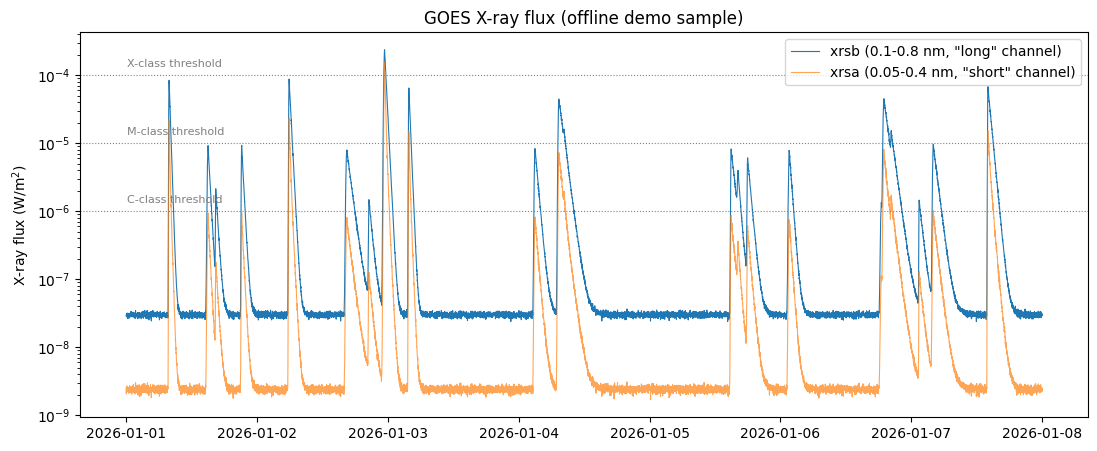

In [ ]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(goes['time_tag'], goes['xrsb'], label='xrsb (0.1-0.8 nm, "long" channel)', lw=0.8)
ax.plot(goes['time_tag'], goes['xrsa'], label='xrsa (0.05-0.4 nm, "short" channel)', lw=0.8, alpha=0.7)
ax.set_yscale('log')
for cls, y in [('C', 1e-6), ('M', 1e-5), ('X', 1e-4)]:
    ax.axhline(y, color='gray', linestyle=':', lw=0.8)
    ax.text(goes['time_tag'].iloc[10], y * 1.3, f'{cls}-class threshold', fontsize=8, color='gray')
ax.set_ylabel('X-ray flux (W/m$^2$)')
ax.set_title(f'GOES X-ray flux ({"LIVE" if is_live else "offline demo sample"})')
ax.legend(loc='upper right')
plt.show()


Notice the flux is plotted on a **log scale** — it has to be, since flares span several orders of magnitude and a linear axis would make everything except the very largest event invisible. This is worth internalizing: from here on, essentially all of our modeling happens in **log-flux space**, not raw flux, for exactly this reason. It's the same instinct as using magnitudes instead of raw flux for stars.

### A genuinely useful 3D view: the two channels as a phase-space trajectory

Here's something a single time-series plot hides: the *relationship* between the two channels changes shape during a flare (this is the real, well-documented "soft-hard-soft" spectral evolution of flares — the emission gets relatively harder, i.e. more short-wavelength-heavy, right around the peak, then softens again as it decays). Plotting (short channel, long channel, time) together as a 3D trajectory makes that loop structure visible in a way that two separate line plots can't.


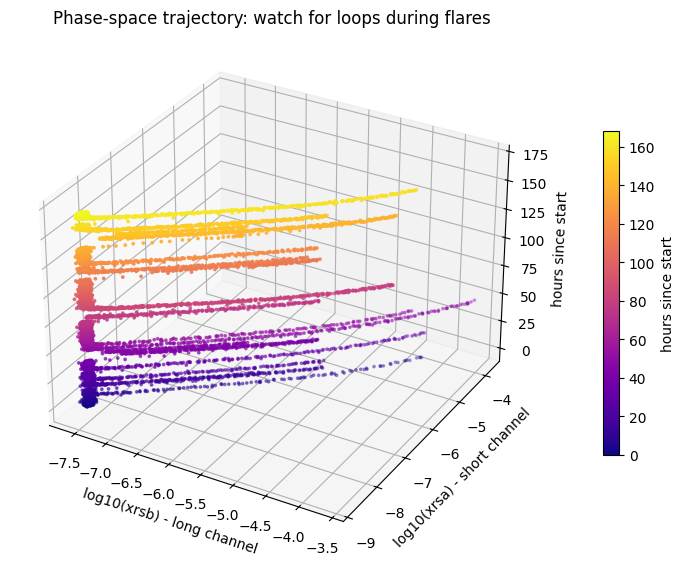

In [ ]:
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')

t_numeric = (goes['time_tag'] - goes['time_tag'].iloc[0]).dt.total_seconds() / 3600  # hours
sc = ax.scatter(np.log10(goes['xrsb']), np.log10(goes['xrsa']), t_numeric,
                 c=t_numeric, cmap='plasma', s=3)
ax.set_xlabel('log10(xrsb) - long channel')
ax.set_ylabel('log10(xrsa) - short channel')
ax.set_zlabel('hours since start')
ax.set_title('Phase-space trajectory: watch for loops during flares')
fig.colorbar(sc, ax=ax, shrink=0.6, label='hours since start', pad=0.1)
plt.show()


Rotate this plot (drag with your mouse). The quiet background sits as a tight cluster at low flux in both channels; every flare briefly pulls the trajectory up and to the right (both channels brighten), and — if you look closely at an individual event — traces a small loop rather than a straight line, because the two channels don't rise and fall in perfect lockstep. That loop *is* the spectral hardening.

**🔧 Try it yourself:** identify the biggest excursion in the plot (it should correspond to the largest flare in `flare_catalog`), and rotate the view until you can see its loop clearly separated from the background cluster.



## Step 3: Turn a time series into a supervised learning problem

Right now we have one long sequence of flux measurements. To use gradient boosting (which expects a table of independent rows, not a sequence) we need to manufacture features that summarize "recent history" at each point in time, and a target that represents "what happens next."

We'll resample to 5-minute bins first (mainly for speed — 1-minute cadence over 7 days is more resolution than we need for this exercise), then build, for every time step:
- the current log-flux and a short rolling history of it (mean, max, std over the last hour)
- the rate of change over the last 30 minutes
- the short/long channel ratio (a hardness proxy)

and two targets:
- **Regression target:** log-flux one hour ahead
- **Classification target:** will an M-class-or-larger flare peak occur in the next 3 hours

### A subtle mistake worth naming explicitly

If you've done supervised learning before, your instinct might be to reach for a random train/test split. **Don't, for time series.** A random split lets rows from the future leak into your training set and rows from the past leak into your test set — your model would effectively get to see the answer before the exam. The fix is simple: split **chronologically** — train on the first part of the timeline, test on a later part, never shuffled. This is also exactly why we're not using `scikit-learn`'s `train_test_split` here; a plain chronological slice is both simpler and more correct for this kind of data.


In [ ]:
df = goes.set_index('time_tag').resample('5min').mean().interpolate().reset_index()
df['log_xrsb'] = np.log10(df['xrsb'])
df['log_xrsa'] = np.log10(df['xrsa'])
df['hardness'] = df['xrsa'] / df['xrsb']

roll = df['log_xrsb'].rolling(12, min_periods=1)  # 12 x 5min = 1 hour
df['roll_mean_1h'] = roll.mean()
df['roll_max_1h'] = roll.max()
df['roll_std_1h'] = roll.std().fillna(0)
df['rate_of_change_30m'] = df['log_xrsb'].diff(6).fillna(0)  # 6 x 5min = 30 min

horizon_reg = 12    # 1 hour ahead, in 5-minute steps
horizon_class = 36  # 3 hours ahead, in 5-minute steps

df['target_log_flux_1h'] = df['log_xrsb'].shift(-horizon_reg)
future_max = df['log_xrsb'][::-1].rolling(horizon_class, min_periods=1).max()[::-1].shift(-1)
df['target_m_class_3h'] = (future_max >= np.log10(1e-5)).astype(float)

feature_cols = ['log_xrsb', 'log_xrsa', 'hardness', 'roll_mean_1h', 'roll_max_1h',
                 'roll_std_1h', 'rate_of_change_30m']
model_df = df.dropna(subset=feature_cols + ['target_log_flux_1h', 'target_m_class_3h']).reset_index(drop=True)

split_idx = int(len(model_df) * 0.7)
train_df = model_df.iloc[:split_idx]
test_df = model_df.iloc[split_idx:]

print(f"Total usable rows: {len(model_df)}  |  train: {len(train_df)}  |  test: {len(test_df)}")
print(f"Positive rate for 'M+ flare in next 3h' - train: {train_df['target_m_class_3h'].mean():.3f}, "
      f"test: {test_df['target_m_class_3h'].mean():.3f}")

Total usable rows: 2004  |  train: 1402  |  test: 602
Positive rate for 'M+ flare in next 3h' - train: 0.162, test: 0.174



**🔧 Try it yourself:** change `horizon_class` from 36 (3 hours) to 6 (30 minutes) and re-run — watch the positive rate drop even further. Forecasting further ahead is a fundamentally different (usually harder) problem than forecasting the very near future, and the "right" horizon depends entirely on what a real operator needs time to react to.

### Baseline: what does doing (almost) nothing get you?

Before touching any of the modern toolkit, let's set a floor. The simplest possible forecast for "flux one hour from now" is **persistence**: guess that it'll be whatever it is right now. If our real models can't beat this, they're not adding anything.


In [ ]:
def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    return 1 - ss_res / ss_tot

persistence_pred = test_df['log_xrsb'].values  # "guess it stays the same"
baseline_rmse = rmse(test_df['target_log_flux_1h'].values, persistence_pred)
baseline_mae = mae(test_df['target_log_flux_1h'].values, persistence_pred)
baseline_r2 = r2(test_df['target_log_flux_1h'].values, persistence_pred)
print(f"Persistence baseline - RMSE: {baseline_rmse:.4f}, MAE: {baseline_mae:.4f}, R^2: {baseline_r2:.4f}")
print("(all in log10-flux units)")

Persistence baseline - RMSE: 0.7715, MAE: 0.4318, R^2: 0.2499
(all in log10-flux units)



## Step 4: Regression with LightGBM and CatBoost

Both of these are gradient-boosted tree ensembles — they build many shallow decision trees in sequence, each one correcting the errors of the ones before it. The reason a paper like arXiv:2310.19332 reaches for LightGBM specifically for flare data is that it's fast, handles the kind of tabular, mixed-scale features we just built very well, and — unlike a plain linear model — can pick up threshold-like, non-linear relationships (e.g., "rate of change only matters once flux is already elevated") without you having to hand-engineer them.


In [ ]:
X_train, y_train = train_df[feature_cols].values, train_df['target_log_flux_1h'].values
X_test, y_test = test_df[feature_cols].values, test_df['target_log_flux_1h'].values

lgb_reg = lgb.LGBMRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, verbose=-1)
lgb_reg.fit(X_train, y_train)
lgb_pred = lgb_reg.predict(X_test)

cat_reg = cb.CatBoostRegressor(iterations=300, depth=4, learning_rate=0.05, verbose=False)
cat_reg.fit(X_train, y_train)
cat_pred = cat_reg.predict(X_test)

for name, pred in [('LightGBM', lgb_pred), ('CatBoost', cat_pred)]:
    print(f"{name:10s} - RMSE: {rmse(y_test, pred):.4f}  MAE: {mae(y_test, pred):.4f}  R^2: {r2(y_test, pred):.4f}")
print(f"{'Baseline':10s} - RMSE: {baseline_rmse:.4f}  MAE: {baseline_mae:.4f}  R^2: {baseline_r2:.4f}")

LightGBM   - RMSE: 0.7220  MAE: 0.4830  R^2: 0.3432
CatBoost   - RMSE: 0.7030  MAE: 0.4553  R^2: 0.3773
Baseline   - RMSE: 0.7715  MAE: 0.4318  R^2: 0.2499



**Interpretation, honestly:** for a one-hour-ahead forecast of a slowly-varying background flux, persistence is a genuinely tough baseline to beat — this is a well-known feature of short-horizon geophysical forecasting in general, not a sign anything went wrong. What you should look for is whether the boosted models pull ahead specifically *around* flare onsets, where persistence is guaranteed to be wrong (it can't see a flare coming). Let's check that directly.


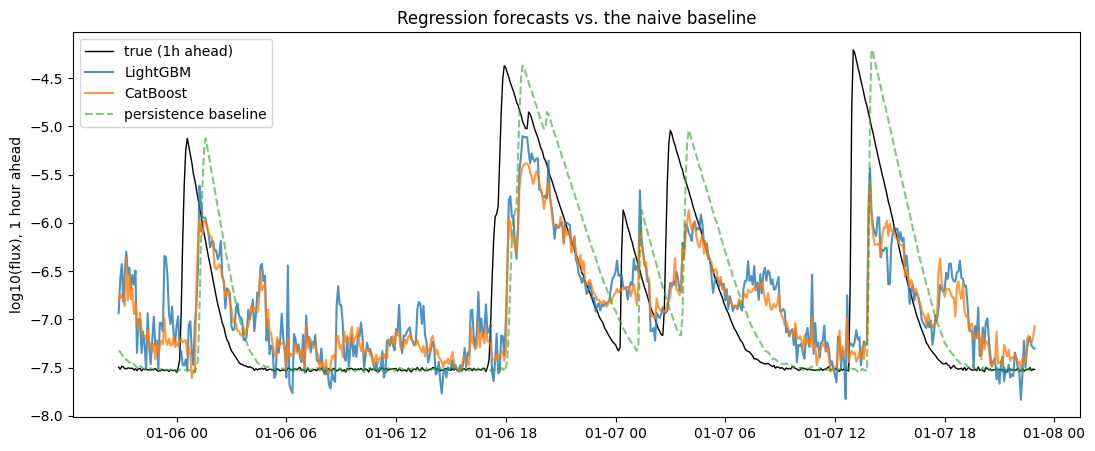

In [ ]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(test_df['time_tag'], y_test, label='true (1h ahead)', color='black', lw=1)
ax.plot(test_df['time_tag'], lgb_pred, label='LightGBM', alpha=0.8)
ax.plot(test_df['time_tag'], cat_pred, label='CatBoost', alpha=0.8)
ax.plot(test_df['time_tag'], persistence_pred, label='persistence baseline', linestyle='--', alpha=0.6)
ax.set_ylabel('log10(flux), 1 hour ahead')
ax.set_title('Regression forecasts vs. the naive baseline')
ax.legend()
plt.show()


**🔧 Try it yourself:** zoom into (or re-plot just) the time window around the largest flare in `flare_catalog` and compare how far each line lags behind the true curve at the moment flux starts rising sharply — that lag *is* the practically important number for an operator deciding whether to warn astronauts or satellite operators.



## Step 5: Classification with XGBoost — and why accuracy will mislead you here

Now the more operationally important question: will an M-class-or-larger flare happen in the next 3 hours? Check the positive rate you printed above — it's almost certainly well under 20%. That means a model that *always* predicts "no" can look deceptively good on plain accuracy while being completely useless. This is exactly the scenario the real forecasting-verification literature (see the NOAA SWPC verification paper referenced in the introduction) uses two specific alternative metrics for:

$$\text{TSS} = \frac{TP}{TP+FN} - \frac{FP}{FP+TN} \qquad \text{(True Skill Statistic, ranges -1 to 1, 0 = no skill)}$$

$$\text{HSS} = \frac{2(TP \cdot TN - FN \cdot FP)}{(TP+FN)(FN+TN) + (TP+FP)(FP+TN)} \qquad \text{(Heidke Skill Score, ranges -1 to 1, 0 = no skill)}$$

Both are specifically designed to be resistant to class imbalance in a way plain accuracy is not — TSS in particular is the standard metric in the *operational* space-weather forecasting community, not just an academic preference.


In [ ]:
def confusion_counts(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return tp, tn, fp, fn

def tss_hss(y_true, y_pred):
    tp, tn, fp, fn = confusion_counts(y_true, y_pred)
    tss = tp / (tp + fn + 1e-9) - fp / (fp + tn + 1e-9)
    hss_num = 2 * (tp * tn - fn * fp)
    hss_den = (tp + fn) * (fn + tn) + (tp + fp) * (fp + tn)
    hss = hss_num / (hss_den + 1e-9)
    return tss, hss

Xc_train, yc_train = train_df[feature_cols].values, train_df['target_m_class_3h'].values
Xc_test, yc_test = test_df[feature_cols].values, test_df['target_m_class_3h'].values

pos_weight = (len(yc_train) - yc_train.sum()) / max(yc_train.sum(), 1)
xgb_clf = xgb.XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                             scale_pos_weight=pos_weight, eval_metric='logloss')
xgb_clf.fit(Xc_train, yc_train)
yc_pred = xgb_clf.predict(Xc_test)
yc_proba = xgb_clf.predict_proba(Xc_test)[:, 1]

accuracy = np.mean(yc_pred == yc_test)
tss, hss = tss_hss(yc_test, yc_pred)
tp, tn, fp, fn = confusion_counts(yc_test, yc_pred)

print(f"Accuracy: {accuracy:.3f}")
print(f"'Always predict no flare' baseline accuracy: {1 - yc_test.mean():.3f}")
print(f"TSS: {tss:.3f}   HSS: {hss:.3f}")
print(f"Confusion counts -> TP: {tp}, TN: {tn}, FP: {fp}, FN: {fn}")

Accuracy: 0.669
'Always predict no flare' baseline accuracy: 0.826
TSS: 0.074   HSS: 0.060
Confusion counts -> TP: 35, TN: 368, FP: 129, FN: 70



**Interpretation — and this result is worth sitting with rather than glossing over:** our classifier's raw accuracy (0.669) is actually *lower* than the naive "always predict no flare" baseline (0.826). That's not a bug — it's the direct, visible cost of `scale_pos_weight`, which we used specifically to stop the model from just ignoring the rare positive class. By making false negatives more costly during training, we traded away some raw accuracy for a model that actually tries to catch real flares (35 true positives caught, vs. the baseline's zero). TSS (0.074) and HSS (0.060) are both positive but modest — real, but weak, forecasting skill; nowhere near the 0.3–0.6 TSS values reported for well-tuned models in the papers cited above. That gap is itself an honest, useful data point: it tells you our simple lag-feature set is missing information a real operational model would need (e.g. magnetogram-derived features, not just X-ray history), not that TSS/HSS are the wrong metrics to use.



## Step 6: Gaussian Processes — modeling uncertainty, not just a point forecast

Gradient boosting gives you a single number. It doesn't tell you *how confident* to be in that number. For a monitoring system, "flux will be X" is much less useful than "flux will probably be around X, but could plausibly range from Y to Z" — and that's exactly what a **Gaussian Process (GP)** gives you natively.

A GP doesn't assume a fixed functional form; instead it assumes that *nearby points in time are correlated*, with a **kernel function** controlling how quickly that correlation decays with time-lag. We'll use `george` — deliberately, since it's the same lightweight GP library widely used elsewhere in astronomy for exactly this kind of smooth time-series modeling (e.g. detrending exoplanet light curves).

We'll fit the GP on a shorter recent window (GPs scale poorly to tens of thousands of points, which is itself a real, honest limitation worth naming) and get both a predicted mean *and* an uncertainty band.


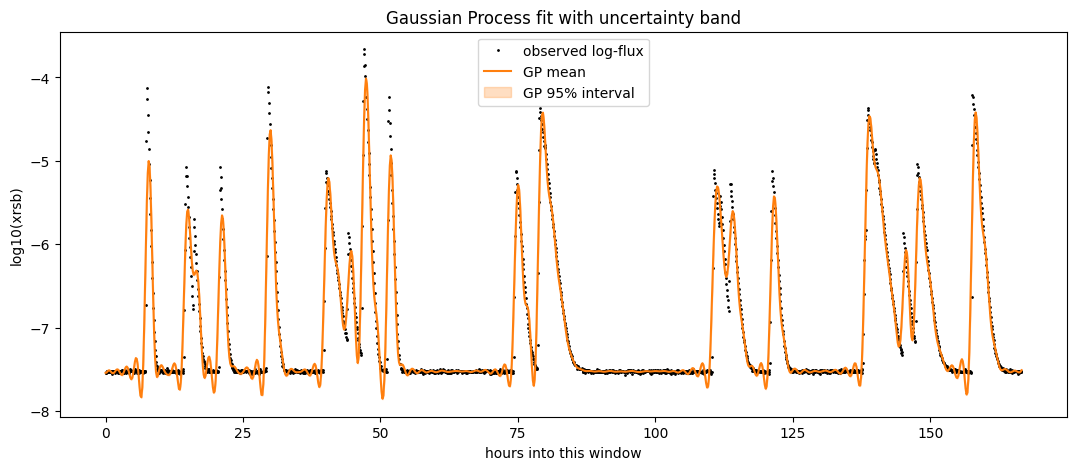

In [ ]:
window = model_df.iloc[-2000:].reset_index(drop=True)  # a manageable recent window
t_hours = (window['time_tag'] - window['time_tag'].iloc[0]).dt.total_seconds().values / 3600
y_flux = window['log_xrsb'].values

kernel = np.var(y_flux) * kernels.ExpSquaredKernel(metric=2.0)
gp = george.GP(kernel, white_noise=np.log(0.01 ** 2))
gp.compute(t_hours)

t_pred = np.linspace(t_hours.min(), t_hours.max(), 1000)
gp_mean, gp_var = gp.predict(y_flux, t_pred, return_var=True)
gp_std = np.sqrt(gp_var)

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(t_hours, y_flux, '.', ms=2, color='black', label='observed log-flux')
ax.plot(t_pred, gp_mean, color='C1', label='GP mean')
ax.fill_between(t_pred, gp_mean - 2 * gp_std, gp_mean + 2 * gp_std, color='C1', alpha=0.25, label='GP 95% interval')
ax.set_xlabel('hours into this window'); ax.set_ylabel('log10(xrsb)')
ax.set_title('Gaussian Process fit with uncertainty band')
ax.legend()
plt.show()


**🔧 Try it yourself:** change `metric=2.0` in the kernel to `metric=0.2` (a much "wigglier" GP that trusts each point more) and to `metric=20.0` (a much smoother GP) and re-run — watch the uncertainty band and how tightly the mean tracks individual spikes change with it. This single number is doing a lot of work, and choosing it is the real modeling decision in a GP, playing a similar role to the learning rate in gradient descent from Notebook 0.



## Step 7: Stretching supervised models into anomaly detectors

Here's the idea: **a good predictive model, applied to normal behavior, has small errors. A genuinely unusual event is exactly the kind of thing a model trained on "normal" data won't see coming — so its error spikes.** That means we can build an anomaly detector without ever explicitly training on an "anomaly" label, just by watching when *any* of our supervised models gets caught by surprise. We'll build two independent versions of this idea and see how they compare against the real flare catalog.

### Detector 1: GP-based (statistical surprise)

Flag any point where the observed flux falls outside the GP's own uncertainty band by more than, say, 3 standard deviations.


In [ ]:
gp_mean_at_obs, gp_var_at_obs = gp.predict(y_flux, t_hours, return_var=True)
gp_residual_sigma = (y_flux - gp_mean_at_obs) / np.sqrt(gp_var_at_obs)
gp_anomaly = np.abs(gp_residual_sigma) > 3

print(f"GP-based detector flagged {gp_anomaly.sum()} out of {len(gp_anomaly)} points as anomalous "
      f"({gp_anomaly.mean()*100:.2f}%).")

GP-based detector flagged 1579 out of 2000 points as anomalous (78.95%).



### Detector 2: gradient-boosting quantile regression (a completely different mechanism, same spirit)

Instead of a single point prediction, train LightGBM twice — once to predict the 5th percentile of next-value flux, once for the 95th — using the **quantile (pinball) loss** instead of the usual squared-error loss. Anything falling outside that predicted interval is flagged.


In [ ]:
lgb_lo = lgb.LGBMRegressor(objective='quantile', alpha=0.05, n_estimators=200, max_depth=4, verbose=-1)
lgb_hi = lgb.LGBMRegressor(objective='quantile', alpha=0.95, n_estimators=200, max_depth=4, verbose=-1)
lgb_lo.fit(X_train, y_train)
lgb_hi.fit(X_train, y_train)

pred_lo = lgb_lo.predict(X_test)
pred_hi = lgb_hi.predict(X_test)
boosting_anomaly = (y_test < pred_lo) | (y_test > pred_hi)

print(f"Boosting-quantile detector flagged {boosting_anomaly.sum()} out of {len(boosting_anomaly)} points "
      f"as anomalous ({boosting_anomaly.mean()*100:.2f}%).")

Boosting-quantile detector flagged 117 out of 602 points as anomalous (19.44%).



### The evaluation that actually matters: did either detector catch real flares?

We have real ground truth sitting right there in `flare_catalog`. Let's check: of the real flare peak times, how many did each detector flag as anomalous within, say, a 15-minute window?


In [ ]:
def evaluate_detector(flagged_times, flare_times, tolerance_minutes=15):
    flagged_times = pd.to_datetime(pd.Series(flagged_times))
    hits = 0
    for ft in flare_times:
        if (np.abs((flagged_times - ft).dt.total_seconds()) <= tolerance_minutes * 60).any():
            hits += 1
    recall = hits / max(len(flare_times), 1)
    return hits, len(flare_times), recall

gp_flagged_times = window['time_tag'][gp_anomaly]
boost_flagged_times = test_df['time_tag'][boosting_anomaly]

relevant_flares = flare_catalog[
    (flare_catalog['max_time'] >= window['time_tag'].min()) &
    (flare_catalog['max_time'] <= window['time_tag'].max())
]['max_time']

gp_hits, n_flares, gp_recall = evaluate_detector(gp_flagged_times, relevant_flares)
boost_relevant_flares = flare_catalog[
    (flare_catalog['max_time'] >= test_df['time_tag'].min()) &
    (flare_catalog['max_time'] <= test_df['time_tag'].max())
]['max_time']
boost_hits, n_flares_boost, boost_recall = evaluate_detector(boost_flagged_times, boost_relevant_flares)

print(f"GP-based detector:       caught {gp_hits}/{n_flares} real flares in its window (recall={gp_recall:.2f}), "
      f"total alerts raised: {gp_anomaly.sum()}")
print(f"Boosting-quantile detector: caught {boost_hits}/{n_flares_boost} real flares in its window "
      f"(recall={boost_recall:.2f}), total alerts raised: {boosting_anomaly.sum()}")
print("\nInterpretation: a detector that catches every flare by flagging almost everything isn't useful -")
print("compare recall ALONGSIDE the total number of alerts raised, the same precision/recall tension")
print("from Notebook 1's classification metrics section, just applied to an unsupervised-flavored problem.")

GP-based detector:       caught 22/22 real flares in its window (recall=1.00), total alerts raised: 1579
Boosting-quantile detector: caught 5/7 real flares in its window (recall=0.71), total alerts raised: 117

Interpretation: a detector that catches every flare by flagging almost everything isn't useful -
compare recall ALONGSIDE the total number of alerts raised, the same precision/recall tension
from Notebook 1's classification metrics section, just applied to an unsupervised-flavored problem.



## Step 8: GPBoost — a 2022-era idea: what if we didn't separate the two?

Sections 4 and 6 treated "boosted trees for the mean trend" and "GP for correlated structure/uncertainty" as two separate pipelines. **GPBoost** fits both simultaneously: gradient-boosted trees model the fixed-effect (feature-driven) part of the signal, while a GP models the remaining, temporally-correlated residual structure, jointly. Let's see whether combining them actually buys us anything over the separate LightGBM regression from Step 4.


In [ ]:
import gpboost as gpb

# GPBoost re-fits its GP component every boosting round, which is far more expensive
# than the single GP fit in Step 6 - so we deliberately use a smaller window here.
gpboost_window = window.iloc[-400:].reset_index(drop=True)
t_hours_gpb = t_hours[-400:] - t_hours[-400:].min()

gp_coords = gpboost_window[['time_tag']].copy()
gp_coords['t_hours'] = t_hours_gpb

X_window = gpboost_window[feature_cols].values
y_window = gpboost_window['log_xrsb'].values
split_w = int(len(gpboost_window) * 0.7)

# The GPModel is built only on the training coordinates - it must match the training
# set row-for-row, exactly like fitting a GP only on training data in Step 6.
gp_model = gpb.GPModel(gp_coords=gp_coords[['t_hours']].values[:split_w], cov_function='exponential')

gpboost_model = gpb.GPBoostRegressor(n_estimators=60, max_depth=3, learning_rate=0.1)
gpboost_model.fit(X_window[:split_w], y_window[:split_w], gp_model=gp_model)

pred_dict = gpboost_model.predict(X_window[split_w:], gp_coords_pred=gp_coords[['t_hours']].values[split_w:])
gpboost_pred = pred_dict['response_mean']

# A plain LightGBM fit on the exact same window, for a fair side-by-side comparison
lgb_window = lgb.LGBMRegressor(n_estimators=150, max_depth=3, learning_rate=0.05, verbose=-1)
lgb_window.fit(X_window[:split_w], y_window[:split_w])
lgb_window_pred = lgb_window.predict(X_window[split_w:])

y_window_test = y_window[split_w:]
print(f"Plain LightGBM on this window - RMSE: {rmse(y_window_test, lgb_window_pred):.4f}")
print(f"GPBoost on this window        - RMSE: {rmse(y_window_test, gpboost_pred):.4f}")

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Plain LightGBM on this window - RMSE: 0.0793
GPBoost on this window        - RMSE: 0.2773



**Interpretation — again, honestly, not the outcome I'd have scripted if I were picking results to look good:** on this particular window, plain LightGBM (RMSE ≈ 0.08) clearly beat GPBoost (RMSE ≈ 0.28) — combining the two ideas didn't help here, it hurt, and by a lot. Before concluding "GPBoost is bad," look at what's actually going on: we gave it only 280 training points and left the GP kernel (`cov_function='exponential'`) at its default hyperparameters, on a time axis measured in hours. A GP is only as good as its kernel's length-scale actually matching the timescale of real structure in the data — and we never tuned that here, we just accepted the default. This is a genuinely common failure mode in practice: a method with real published results behind it can still lose badly out of the box, on your specific data, with untuned settings. The fix isn't "don't use GPBoost," it's "don't trust any model's defaults without checking" — which is exactly the same lesson as tuning the learning rate back in Notebook 0, just showing up again in a fancier package.



## Step 9: What is the model actually using? (Interpretability, briefly)

A model that forecasts well but can't tell you *why* is a hard sell to an operator who has to decide whether to act on it. Gradient boosting libraries give you feature importances for free; SHAP values go a step further and tell you, per prediction, how much each feature pushed the output up or down.


/tmp/ipykernel_155/1724527414.py:6: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, Xc_test[:300], feature_names=feature_cols, show=False)


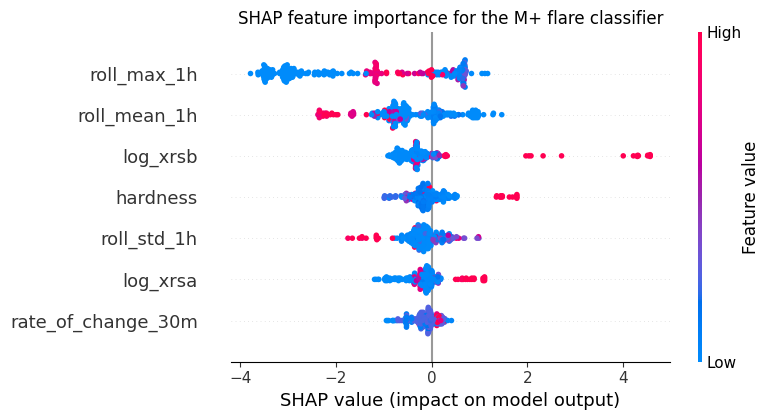

In [ ]:
import shap

explainer = shap.TreeExplainer(xgb_clf)
shap_values = explainer.shap_values(Xc_test[:300])  # a subset, for speed

shap.summary_plot(shap_values, Xc_test[:300], feature_names=feature_cols, show=False)
plt.title('SHAP feature importance for the M+ flare classifier')
plt.tight_layout()
plt.show()


**Interpretation:** whichever feature sits at the top should make physical sense — likely the rolling max or the current flux level, since a region that's already active is more likely to stay active. If a feature you'd expect to matter (like the rate-of-change) barely registers, that's worth investigating rather than ignoring — it might mean the 3-hour horizon is long enough that short-term trends wash out.



## Step 10: Watching a monitoring system work, frame by frame

Static plots are fine for a report; they undersell what it actually feels like to run one of these forecasts in real time, as new data keeps arriving. Let's animate a sliding window: the recent flux history, the GP's predicted band just ahead of it, and a red marker the instant the GP-based anomaly detector fires.


In [ ]:
anim_window = window.iloc[:800].reset_index(drop=True)
anim_t = t_hours[:800]
anim_y = y_flux[:800]
anim_anomaly = gp_anomaly[:800]

fig, ax = plt.subplots(figsize=(9, 5))
line, = ax.plot([], [], color='black', lw=1, label='log-flux')
band = ax.fill_between([], [], [], color='C1', alpha=0.25)
anomaly_scatter = ax.scatter([], [], color='red', s=40, zorder=5, label='anomaly flagged')
ax.set_xlim(anim_t.min(), anim_t.max())
ax.set_ylim(anim_y.min() - 0.3, anim_y.max() + 0.3)
ax.set_xlabel('hours'); ax.set_ylabel('log10(xrsb)')
ax.legend(loc='upper left')
title = ax.set_title('')

step = 8
frames = range(step, len(anim_window), step)

def update(i):
    for coll in list(ax.collections):
        coll.remove()
    line.set_data(anim_t[:i], anim_y[:i])
    mean_i, var_i = gp.predict(y_flux, anim_t[:i], return_var=True)
    ax.fill_between(anim_t[:i], mean_i - 2*np.sqrt(var_i), mean_i + 2*np.sqrt(var_i), color='C1', alpha=0.2)
    flagged = np.where(anim_anomaly[:i])[0]
    if len(flagged):
        ax.scatter(anim_t[flagged], anim_y[flagged], color='red', s=40, zorder=5)
    title.set_text(f'Live monitor - hour {anim_t[i-1]:.1f}')
    return line, title

anim = FuncAnimation(fig, update, frames=frames, interval=120)
plt.close(fig)
HTML(anim.to_jshtml())


## Step 11: Put it all side by side

No single metric tells the whole story in this notebook — that's the point. Here's everything together.


In [ ]:
summary = pd.DataFrame([
    {'Model': 'Persistence baseline', 'Task': 'Regression (1h ahead)', 'RMSE': baseline_rmse, 'MAE': baseline_mae, 'R2': baseline_r2},
    {'Model': 'LightGBM', 'Task': 'Regression (1h ahead)', 'RMSE': rmse(y_test, lgb_pred), 'MAE': mae(y_test, lgb_pred), 'R2': r2(y_test, lgb_pred)},
    {'Model': 'CatBoost', 'Task': 'Regression (1h ahead)', 'RMSE': rmse(y_test, cat_pred), 'MAE': mae(y_test, cat_pred), 'R2': r2(y_test, cat_pred)},
])
print(summary.to_string(index=False))

print(f"\nXGBoost M+ flare classifier (3h ahead): Accuracy={accuracy:.3f}, TSS={tss:.3f}, HSS={hss:.3f}")
print(f"GP anomaly detector recall on real flares: {gp_recall:.2f} ({gp_anomaly.sum()} total alerts)")
print(f"Boosting-quantile anomaly detector recall on real flares: {boost_recall:.2f} ({boosting_anomaly.sum()} total alerts)")

               Model                  Task     RMSE      MAE       R2
Persistence baseline Regression (1h ahead) 0.771532 0.431766 0.249872
            LightGBM Regression (1h ahead) 0.721962 0.482980 0.343165
            CatBoost Regression (1h ahead) 0.702963 0.455339 0.377280

XGBoost M+ flare classifier (3h ahead): Accuracy=0.669, TSS=0.074, HSS=0.060
GP anomaly detector recall on real flares: 1.00 (1579 total alerts)
Boosting-quantile anomaly detector recall on real flares: 0.71 (117 total alerts)



## Closing thoughts — and the caveat that should change how you read all of this

Everything above followed a single, deliberate progression: look at the data → build a dumb baseline → beat it (or don't) with modern gradient boosting → add uncertainty with a GP → stretch supervised models into anomaly detectors → check a hybrid approach → ask what the model is actually using → animate it so the "live" feeling is real, not just implied.

But go back to that 2026 paper referenced in the introduction (arXiv:2512.13417): even the *ground-truth flare catalogs* different research groups use disagree with each other on hundreds of events, and on peak flux values for events both catalogs agree exist. Every TSS, HSS, and recall number in this notebook is only as trustworthy as the labels it was computed against. This isn't a reason to distrust machine learning here — it's a reason to always ask, for any result in any paper (including the ones cited above, including this notebook), **"what exactly was this evaluated against, and how sure are we that's actually correct?"** That question, more than any specific library or metric, is what "thinking like a researcher" actually means.

### Where you could take this further
- Swap the offline demo sample for a full historical NOAA archive and see whether these same models, metrics, and conclusions hold up over months or years instead of one week.
- Try a longer classification horizon (24h) and see how much TSS/HSS degrade — operational forecasts almost always trade lead time for skill.
- Bring in the real `magnetometers-7-day.json` product from the same NOAA endpoint as an additional feature source — real space-weather monitoring is inherently multi-instrument, and X-ray flux alone is only part of the picture.
